# V2X Misbehaviour Detection

**Module 05 · Cybersecurity (ISO/SAE 21434)** · Notebook 5 of 5

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/05_Cybersecurity_ISO21434/05_v2x_misbehaviour_detection.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Advanced | [TARA](02_tara.ipynb), [CAN intrusion detection](04_can_bus_intrusion_detection.ipynb), [V2X and cooperative driving](../07_Runtime_Assurance_and_Operations/04_v2x_cooperative_driving.ipynb) | ISO/SAE 21434:2021, UN R155, ETSI TS 103 759, ETSI TR 103 460, ETSI TS 103 097, IEEE 1609.2-2022, ETSI EN 302 637-2 |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

After working through this notebook you will be able to:

1. Explain why a correctly **signed** V2X message can still be **false**, and how falsified position or speed reaches cooperative perception and an AEB function.
2. Load the **VeReMi Extension** benchmark (simulated, with labelled attacks), and state what simulation-based benchmark data can and cannot show.
3. Implement the classic local plausibility checks — acceptance range (ART), sudden appearance (SAW), speed plausibility, position–speed consistency, beacon frequency and a **Kalman-filter** consistency test — and a **learned** detector built on them.
4. Evaluate detectors per attack type with a **time-separated** split: detection per attacker, false-positive rate per genuine sender, detection latency and compute cost.
5. Show what **on-board sensor cross-checks** add for attacks that are internally consistent, and place local detection in the ETSI misbehaviour-reporting chain and in the TARA of [notebook 2](02_tara.ipynb).

## 1. Setup

In [1]:
# Course toolkit (tables, formulas and real-data loaders). Installs automatically on Colab.
try:
    import avsafety
except ImportError:
    %pip install -q "avsafety[data] @ git+https://github.com/milinpatel07/Autonomous-Driving_AI-Safety-and-Security.git"
    import avsafety
from avsafety import data as D
from avsafety import iso21434 as S

import os, time
os.environ.setdefault("OMP_NUM_THREADS", "2")            # keep scikit-learn polite on shared CPUs
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier

SEED = 42
rng = np.random.default_rng(SEED)
OKABE_ITO = ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7", "#000000"]
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 170)

## 2. Why falsified V2X data is a safety problem

A CAM (ETSI EN 302 637-2) or BSM (SAE J2735) is **signed** with a pseudonym certificate (an *authorisation ticket*, ETSI
TS 103 097 / IEEE 1609.2). The signature proves that the sender holds a valid certificate — not that what it says is true.
An **insider** (a compromised on-board unit, a manipulated GNSS input, or a faulty sensor) can sign false data. The receiver
must therefore judge the *content*: this is **misbehaviour detection**.

The safety link is direct once V2X feeds perception. In cooperative perception, a received vehicle state becomes an object
in the ego vehicle's environment model; in the AEB example of this course:

* a **phantom** vehicle placed in the ego path can request braking that nothing justifies — the hazard behind **SG-01**
  (avoid unintended AEB deceleration, ASIL D, FTTI 300 ms; [HARA](../03_Functional_Safety_ISO26262/02_hara.ipynb));
* a real vehicle **moved out** of the path, or reported at the wrong speed, can suppress or delay a needed intervention —
  **SG-02** (avoid omission, ASIL B).

[Notebook 07-04](../07_Runtime_Assurance_and_Operations/04_v2x_cooperative_driving.ipynb) argues that V2X should enter
the safety case as an *additional*, non-safety-critical input unless it carries safety requirements of its own. This
notebook measures how well the receiver can tell true from false — the evidence either argument needs.

## 3. The data: VeReMi Extension (simulated benchmark)

**What it is.** VeReMi Extension (Kamel et al., 2020) is the reference benchmark for V2X misbehaviour detection. Logs come
from the **F2MD** framework on VEINS/OMNeT++ and SUMO, on a 1.61 km² part of the LuST traffic scenario of Luxembourg City,
with sensor-error models for position, speed, acceleration and heading. 30 % of vehicles misbehave. Each attack type is a
separate subset with two simulated hours; we use the 14:00–16:00 (lighter traffic) subsets.

**What it is not.** These are **real benchmark data from a calibrated simulation, not field measurements.** Radio
propagation, GNSS errors and driver behaviour are models; reception time equals sending time in the logs; there is no
real on-board sensor data. Results transfer to vehicles only as far as those models hold — say so in any report that
uses them.

**Access and licence.** Zenodo record 20090854, **CC BY 4.0**, no login. Each attack subset is a 120–850 MB zip of zips;
`D.veremi(...)` reads **individual receiver logs** out of it by HTTP range requests, so this notebook downloads about
60 MB once (including one ground-truth file) and caches it. Labels: every message is labelled with the attacker type of its sender, taken from the log file
names (`traceJSON-<vehicle>-<module>-A<type>-…`); type 0 is genuine. The original VeReMi (2018) and the newer VeReMi
NextGen (2026, 15 attack types) are on Zenodo under the same licence.

**Split.** Thresholds and the learned model are fitted on the **first simulated hour**; everything is evaluated on the
**second hour** — different vehicles, later time, no message in both sets. Per hour we read the logs of the first 40
genuine receivers, which cover the first 6–8 simulated minutes of that hour.

In [2]:
SUBSETS = ["ConstPos", "ConstPosOffset", "RandomPosOffset", "ConstSpeedOffset", "EventualStop", "DataReplay", "DoS"]
N_RECEIVERS = 40

def load(hour):
    parts = [D.veremi(a, density="1416", hour=hour, n_receivers=N_RECEIVERS).assign(subset=a) for a in SUBSETS]
    return pd.concat(parts, ignore_index=True)

t0 = time.time()
raw = {h: load(h) for h in (0, 1)}
print(D.attribution("VeReMi Extension"))
print(f"Loaded in {time.time() - t0:.0f} s")

ov = []
for h, df in raw.items():
    rx = df[df.type == 3]
    g = rx.groupby("subset", sort=False)
    ov.append(pd.DataFrame({"hour": h, "receivers": g.receiver.nunique(), "senders": g.sender.nunique(),
                            "messages": g.size(), "attack_share": g.apply(lambda x: (x.attacker_type > 0).mean()).round(3),
                            "sim_minutes": g.apply(lambda x: (x.rcv_time.max() - x.rcv_time.min()) / 60).round(0)}))
print(pd.concat(ov).to_string())

Data: VeReMi Extension V2X misbehaviour dataset, Institute of Distributed Systems, Ulm University (Kamel et al., IEEE ICC 2020, doi:10.1109/ICC40277.2020.9149132), simulated with VEINS/SUMO (LuST scenario), CC BY 4.0, https://doi.org/10.5281/zenodo.20090854
Loaded in 5 s
                  hour  receivers  senders  messages  attack_share  sim_minutes
subset                                                                         
ConstPos             0         40       94     18201         0.359          6.0
ConstPosOffset       0         40       94     18201         0.359          6.0
RandomPosOffset      0         40       94     18201         0.359          6.0
ConstSpeedOffset     0         40       94     18201         0.359          6.0
EventualStop         0         40       94     18201         0.359          6.0
DataReplay           0         40       94     18201         0.359          6.0
DoS                  0         40       95     31401         0.628          6.0
ConstPos

### Preparing receiver-side tracks

Each receiver sees a stream of beacons. We group them into **tracks** per (receiver, pseudonym), attach the receiver's
own GNSS position at reception time, and compute what every check needs: distance to the ego vehicle, claimed speed,
time since the previous beacon of the same pseudonym, and the displacement between consecutive beacons.

In [3]:
def prepare(df):
    own = (df[df.type == 2][["subset", "receiver", "rcv_time", "pos_x", "pos_y", "hed_x", "hed_y", "spd_x", "spd_y"]]
           .rename(columns=lambda c: "ego_" + c if c not in ("subset", "receiver") else c).sort_values("ego_rcv_time"))
    m = df[df.type == 3].sort_values("rcv_time")
    m = pd.merge_asof(m, own, left_on="rcv_time", right_on="ego_rcv_time", by=["subset", "receiver"], direction="backward")
    m = m.sort_values(["subset", "receiver", "sender_pseudo", "rcv_time"]).reset_index(drop=True)
    g = m.groupby(["subset", "receiver", "sender_pseudo"])
    m["first"] = g.cumcount() == 0
    for c in ["rcv_time", "pos_x", "pos_y", "spd_x", "spd_y"]:
        m["prev_" + c] = g[c].shift()
    m["dt"] = m.rcv_time - m.prev_rcv_time
    m["dist_ego"] = np.hypot(m.pos_x - m.ego_pos_x, m.pos_y - m.ego_pos_y)
    m["speed"] = np.hypot(m.spd_x, m.spd_y)
    m["disp"] = np.hypot(m.pos_x - m.prev_pos_x, m.pos_y - m.prev_pos_y)
    vbar = (m.speed + np.hypot(m.prev_spd_x, m.prev_spd_y)) / 2
    m["speed_resid"] = np.abs(m.disp / m.dt - vbar)          # m/s: implied minus claimed speed
    m["y"] = (m.attacker_type > 0).astype(int)
    return m

msgs = {h: prepare(df) for h, df in raw.items()}
tr, te = msgs[0], msgs[1]
print(f"Training (hour 1 of the simulation): {len(tr):,} received beacons; test (hour 2): {len(te):,}")
gen = tr[tr.y == 0]
print(f"Genuine beacons: claimed speed up to {gen.speed.max():.1f} m/s, receiver-sender distance up to "
      f"{gen.dist_ego.max():.0f} m, median beacon interval {gen.dt.median():.2f} s")

Training (hour 1 of the simulation): 140,607 received beacons; test (hour 2): 81,628
Genuine beacons: claimed speed up to 16.9 m/s, receiver-sender distance up to 426 m, median beacon interval 1.00 s


### What the attacks look like to one receiver

The position attacks are described in the original VeReMi paper (van der Heijden et al., 2018): *constant* (a fixed
position), *constant offset* (a fixed offset added to the true position), *random offset* (a new random offset per
message) and *eventual stop* (normal behaviour, then the same position repeatedly, as if stopped). VeReMi Extension adds
speed attacks, replay, denial of service and Sybil variants. Rather than quote parameters, we measure them: the table
compares each attacker's claims with genuine behaviour in the training hour.

                  beacons  median_interval_s  median_speed  median_dist_ego  median_speed_resid
subset                                                                                         
ConstPos             6543               1.00         11.75           816.47               11.72
ConstPosOffset       6543               1.00         11.75           132.05                0.10
ConstSpeedOffset     6543               1.00         10.50            84.68                7.62
DataReplay           6543               1.00         11.69            87.69               12.16
DoS                 19722               0.25         11.74            81.62               12.14
EventualStop         6543               1.00          0.00           345.63                0.00
RandomPosOffset      6543               1.00         11.75            88.07               27.07
(genuine)           81627               1.00         11.67            87.76                0.10


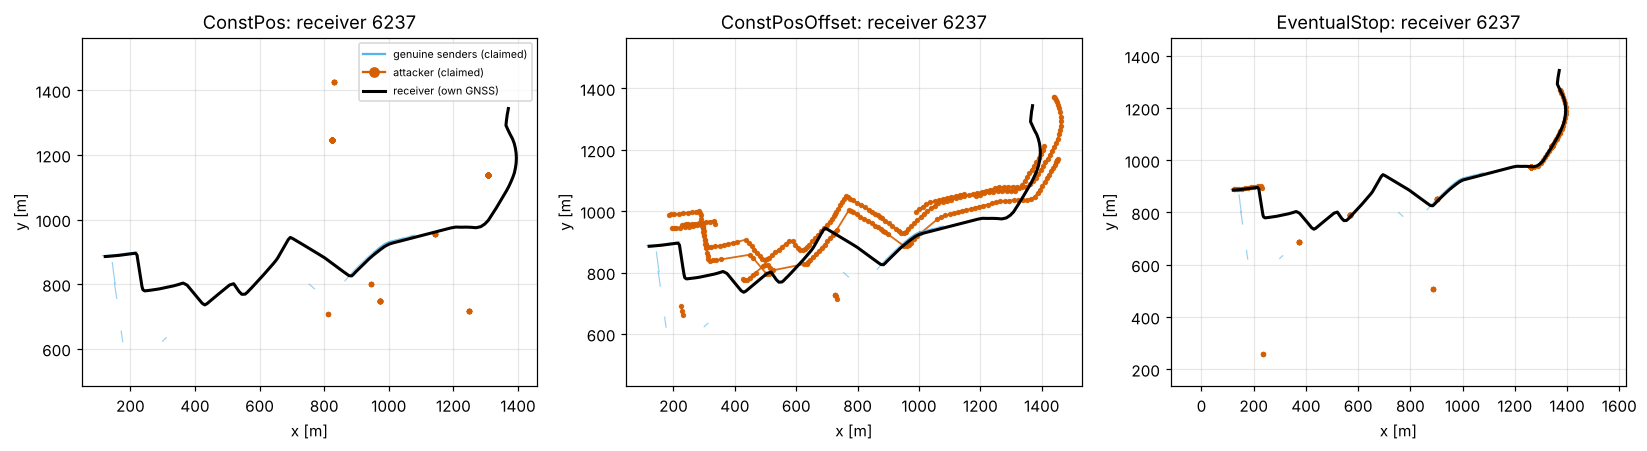

In [4]:
att_profile = tr[tr.y == 1].groupby("subset", sort=False).agg(
    beacons=("y", "size"), median_interval_s=("dt", "median"), median_speed=("speed", "median"),
    median_dist_ego=("dist_ego", "median"), median_speed_resid=("speed_resid", "median"))
att_profile.loc["(genuine)"] = [len(gen), gen.dt.median(), gen.speed.median(), gen.dist_ego.median(), gen.speed_resid.median()]
print(att_profile.round(2).to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, sub in zip(axes, ["ConstPos", "ConstPosOffset", "EventualStop"]):
    d = te[te.subset == sub]
    rx = d.groupby("receiver").y.sum().idxmax()                     # the receiver that heard most attacker beacons
    d = d[d.receiver == rx]
    for (pseudo, y), tr_ in d.groupby(["sender_pseudo", "y"]):
        ax.plot(tr_.pos_x, tr_.pos_y, "-" if y == 0 else "o-", ms=2.5, lw=0.8 if y == 0 else 1.2,
                color=OKABE_ITO[1] if y == 0 else OKABE_ITO[5], alpha=0.6 if y == 0 else 0.9)
    ego = raw[1][(raw[1].subset == sub) & (raw[1].receiver == rx) & (raw[1].type == 2)]
    ax.plot(ego.pos_x, ego.pos_y, color="black", lw=2.0)
    ax.set_title(f"{sub}: receiver {rx}"); ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]"); ax.set_aspect("equal", "datalim")
axes[0].plot([], [], color=OKABE_ITO[1], label="genuine senders (claimed)")
axes[0].plot([], [], "o-", color=OKABE_ITO[5], label="attacker (claimed)")
axes[0].plot([], [], color="black", lw=2, label="receiver (own GNSS)")
axes[0].legend(fontsize=7, loc="best")
plt.tight_layout(); plt.show()

### How often would a falsified beacon reach the AEB?

A simple test of safety relevance: transform each claimed position into the receiver's frame and ask whether it would
place a vehicle **in the ego path** (0–40 m ahead, within ±1.8 m laterally) with a time-to-collision below 2 s. If V2X
objects were trusted without confirmation, such a beacon could request braking. The geometry and the 2 s threshold are
illustrative, not the parameters of a production AEB.

In [5]:
def in_path_ttc(m, x_max=40.0, half_width=1.8, ttc_max=2.0):
    h = np.c_[m.ego_hed_x, m.ego_hed_y]
    h = h / np.linalg.norm(h, axis=1, keepdims=True)
    rel = np.c_[m.pos_x - m.ego_pos_x, m.pos_y - m.ego_pos_y]
    lon = (rel * h).sum(1); lat = rel[:, 0] * h[:, 1] - rel[:, 1] * h[:, 0]
    v_ego = np.hypot(m.ego_spd_x, m.ego_spd_y).to_numpy()
    v_obj_lon = (np.c_[m.spd_x, m.spd_y] * h).sum(1)
    closing = v_ego - v_obj_lon
    ttc = np.where(closing > 0.1, lon / np.maximum(closing, 0.1), np.inf)
    return (lon > 0) & (lon < x_max) & (np.abs(lat) < half_width) & (ttc < ttc_max)

te["aeb_relevant"] = in_path_ttc(te)
rel = te.groupby(["subset", "y"]).aeb_relevant.mean().unstack("y").rename(columns={0: "genuine", 1: "attacker"})
rel["ratio"] = rel.attacker / rel.genuine
print("Share of beacons that would put a vehicle in the ego path with TTC < 2 s:")
print((rel[["genuine", "attacker"]] * 100).round(2).astype(str).add(" %").join(rel.ratio.round(1)).to_string())

Share of beacons that would put a vehicle in the ego path with TTC < 2 s:
                 genuine attacker  ratio
subset                                  
ConstPos          0.19 %    0.0 %    0.0
ConstPosOffset    0.13 %   0.11 %    0.8
ConstSpeedOffset  0.16 %   0.13 %    0.8
DataReplay        0.15 %   0.26 %    1.8
DoS               0.16 %   0.09 %    0.6
EventualStop      0.22 %   0.63 %    2.9
RandomPosOffset   0.22 %   0.13 %    0.6


Genuine beacons also produce such situations — real vehicles ahead, which is why V2X is useful. Among the attacks,
*eventual stop* and *data replay* put a vehicle in the ego path markedly more often than genuine traffic does: a sender
that claims to stand still in a lane the receiver later drives through is exactly the phantom obstacle behind SG-01.
A constant position far outside the road network never does. Which attacks are dangerous depends on the function that
consumes the data — a point for the TARA, not only for the detector.

## 4. Local plausibility checks

ETSI TS 103 759 V2.1.1 (2023-01), clause 6.2 (Table 2), classifies the individual detectors of the *local misbehaviour
detection service* into five classes: (1) implausible values within the message, (2) inconsistency with previous
messages from the same station, (3) inconsistency with the receiver's knowledge of the local environment (e.g. map/LDM),
(4) inconsistency with the receiver's **on-board sensors**, (5) inconsistency with other messages or other stations.
Its informative Annex D (Table D.1) lists example detectors for CAMs. The checks below use only the received messages and
the receiver's own GNSS position:

| Check | Rule (alarm if …) | Origin | TS 103 759 Table D.1 entry (class) |
|---|---|---|---|
| ART — acceptance range | claimed position farther from the receiver than the radio can reach | Leinmüller et al.; definitions as in VeReMi (2018) | position outside own communications coverage area (1) |
| SAW — sudden appearance | first beacon of a pseudonym claims a position very close to the receiver | Schmidt et al.; as in VeReMi (2018) | no direct entry |
| Speed plausibility | claimed speed above any value seen for the vehicle type | — | speed value too high (1) |
| SSC — position–speed consistency | speed implied by the displacement between two beacons differs from the claimed speed | VeReMi (2018) "simple speed check" | change of position inconsistent with speed (2) |
| Beacon frequency | beacons of one pseudonym arrive faster than the generation rules allow | — | beacon frequency too high (2) |
| Kalman consistency | normalised innovation of a constant-velocity Kalman filter too large | Stübing et al., as cited in VeReMi (2018) | change of position / speed inconsistent (2) |

Every threshold is learned on the **genuine** beacons of the training hour (maximum or 99.9 % quantile, with a margin).

In [6]:
def kalman_nis(m, q=1.0):
    # Normalised innovation squared of a constant-velocity Kalman filter per track; measurement = position + velocity,
    # with the sender's stated noise as measurement noise. Tracks are re-initialised after a gap of more than 3 s.
    nis = np.full(len(m), np.nan)
    Z = m[["pos_x", "pos_y", "spd_x", "spd_y"]].to_numpy(); t = m.rcv_time.to_numpy()
    Rn = m[["pos_noise_x", "pos_noise_y", "spd_noise_x", "spd_noise_y"]].to_numpy()
    key = pd.factorize(pd.MultiIndex.from_frame(m[["subset", "receiver", "sender_pseudo"]]))[0]
    bounds = np.r_[0, np.flatnonzero(np.diff(key)) + 1, len(m)]
    P0 = np.diag([25.0, 25.0, 4.0, 4.0]); I4 = np.eye(4)
    for a, b in zip(bounds[:-1], bounds[1:]):
        x, P = Z[a].copy(), P0.copy()
        for i in range(a + 1, b):
            dt = t[i] - t[i - 1]
            if dt > 3.0:
                x, P = Z[i].copy(), P0.copy(); continue
            F = I4.copy(); F[0, 2] = F[1, 3] = dt
            G = np.array([[dt * dt / 2, 0], [0, dt * dt / 2], [dt, 0], [0, dt]])
            x = F @ x; P = F @ P @ F.T + q * q * (G @ G.T)
            Sinv = np.linalg.inv(P + np.diag(np.maximum(Rn[i] ** 2, [1.0, 1.0, 0.01, 0.01])))
            v = Z[i] - x
            nis[i] = v @ Sinv @ v
            K = P @ Sinv; x = x + K @ v; P = (I4 - K) @ P
    return nis

t0 = time.time()
for m in (tr, te):
    m["nis"] = kalman_nis(m)
kf_us = (time.time() - t0) / (len(tr) + len(te)) * 1e6

g = tr[tr.y == 0]
LIM = {"ART_m": 1.05 * g.dist_ego.max(),
       "SAW_m": g[g["first"]].dist_ego.quantile(0.001),
       "vmax_mps": 1.2 * g.speed.max(),
       "SSC_mps": g.speed_resid[g.dt <= 2].quantile(0.999),
       "min_interval_s": 0.9 * g.dt.min(),
       "NIS": np.nanquantile(g.nis, 0.999)}
print({k: round(float(v), 2) for k, v in LIM.items()})
print(f"Kalman filter: {kf_us:.0f} microseconds per beacon in plain Python")

CHECKS = ["ART", "SAW", "speed", "SSC", "frequency", "Kalman"]
def run_checks(m):
    return pd.DataFrame({
        "ART": m.dist_ego > LIM["ART_m"],
        "SAW": m["first"] & (m.dist_ego < LIM["SAW_m"]),
        "speed": m.speed > LIM["vmax_mps"],
        "SSC": (m.speed_resid > LIM["SSC_mps"]) & (m.dt <= 2),
        "frequency": m.dt < LIM["min_interval_s"],
        "Kalman": m.nis > LIM["NIS"],
    }, index=m.index)

for m in (tr, te):
    flags = run_checks(m)
    for c in CHECKS:
        m["f_" + c] = flags[c].to_numpy()
    m["f_any"] = flags.any(axis=1).to_numpy()

{'ART_m': 447.55, 'SAW_m': 3.41, 'vmax_mps': 20.32, 'SSC_mps': 3.19, 'min_interval_s': 0.9, 'NIS': 332.27}
Kalman filter: 19 microseconds per beacon in plain Python


## 5. Evaluation per attack type

Misbehaviour reporting is about **stations**, not single packets: the receiver wants to know *which sender* lies, and how
soon. We therefore score each (receiver, sender) pair in the test hour:

* **detection rate** — share of attacker senders flagged at least once by that receiver;
* **false-positive rate** — share of genuine senders flagged at least once (each would become a false report);
* **latency** — time from the first beacon a receiver hears from an attacker to the first flag (median, in seconds; at
  1 Hz beaconing, one second is one beacon).

Message-level recall is also printed, with a caveat: an eventual-stop attacker sends genuine-looking beacons before it
"stops", yet all its beacons carry the attacker label.

In [7]:
def pair_scores(m, col):
    g = m.groupby(["subset", "receiver", "sender"])
    P = pd.DataFrame({"y": g.y.max(), "flag": g[col].max(), "t0": g.rcv_time.min()})
    P["latency_s"] = m[m[col]].groupby(["subset", "receiver", "sender"]).rcv_time.min() - P.t0
    out = P.groupby("subset", sort=False).apply(lambda x: pd.Series({
        "detection": x.flag[x.y == 1].mean(), "fpr": x.flag[x.y == 0].mean(),
        "latency_s": x.latency_s[(x.y == 1) & x.flag].median(), "attackers": int((x.y == 1).sum())}))
    out["msg_recall"] = m[m.y == 1].groupby("subset", sort=False)[col].mean()
    return out

score_tables = {c: pair_scores(te, "f_" + c) for c in CHECKS + ["any"]}
det = pd.DataFrame({c: s.detection for c, s in score_tables.items()}).loc[SUBSETS]
fpr = pd.DataFrame({c: s.fpr for c, s in score_tables.items()}).mean()
print("Detection rate per attacker (test hour):")
print(det.round(2).to_string())
print("\nFalse-positive rate per genuine sender (mean over subsets):")
print(fpr.round(3).to_string())
print("\nUnion of all checks, per attack type:")
print(score_tables["any"].round(3).to_string())

Detection rate per attacker (test hour):
                   ART   SAW  speed   SSC  frequency  Kalman   any
subset                                                            
ConstPos          0.79  0.00   0.00  0.89       0.00    0.50  0.96
ConstPosOffset    0.04  0.00   0.00  0.01       0.00    0.03  0.08
RandomPosOffset   0.01  0.01   0.00  0.90       0.00    0.09  0.90
ConstSpeedOffset  0.00  0.00   0.38  0.90       0.00    0.46  0.93
EventualStop      0.56  0.00   0.00  0.21       0.00    0.00  0.64
DataReplay        0.43  0.13   0.00  0.83       0.00    0.79  0.85
DoS               0.00  0.00   0.00  0.96       0.97    0.25  0.97

False-positive rate per genuine sender (mean over subsets):
ART          0.000
SAW          0.000
speed        0.000
SSC          0.011
frequency    0.000
Kalman       0.016
any          0.026

Union of all checks, per attack type:
                  detection    fpr  latency_s  attackers  msg_recall
subset                                                

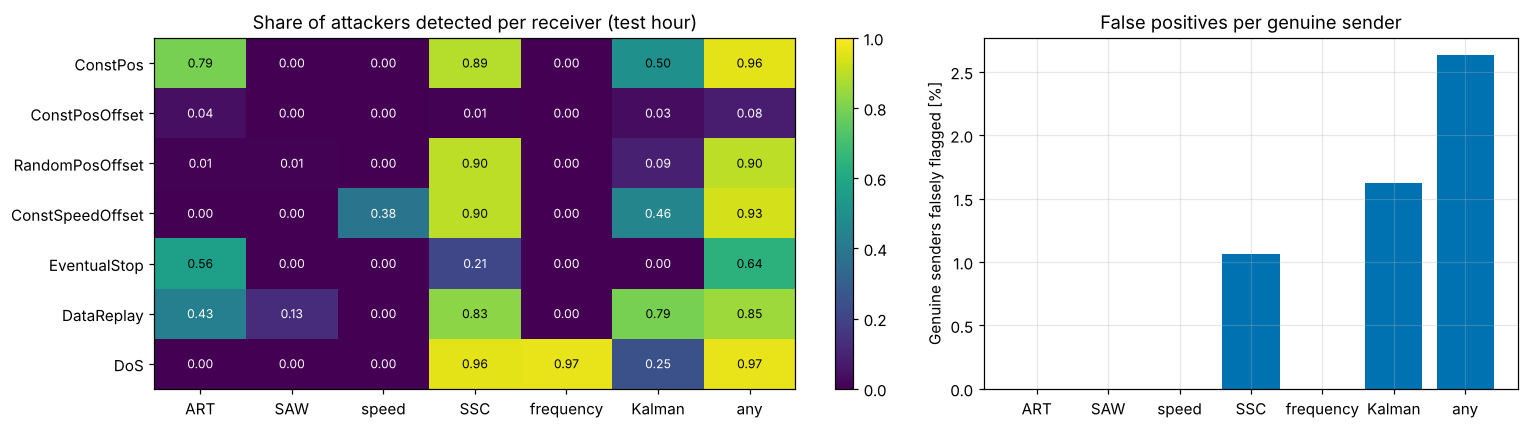

Hardest attack for single-sender checks: ConstPosOffset (union detects 8% of attackers).


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.0), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
im = ax.imshow(det.to_numpy(), cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(det.shape[1]), det.columns); ax.set_yticks(range(det.shape[0]), det.index)
for (r, c), v in np.ndenumerate(det.to_numpy()):
    ax.text(c, r, f"{v:.2f}", ha="center", va="center", color="white" if v < 0.5 else "black", fontsize=8)
ax.set_title("Share of attackers detected per receiver (test hour)"); ax.grid(False)
fig.colorbar(im, ax=ax)
ax = axes[1]
ax.bar(fpr.index, 100 * fpr.to_numpy(), color=OKABE_ITO[4])
ax.set_ylabel("Genuine senders falsely flagged [%]"); ax.set_title("False positives per genuine sender")
plt.tight_layout(); plt.show()
hard = det["any"].idxmin()
print(f"Hardest attack for single-sender checks: {hard} (union detects {det.loc[hard, 'any']:.0%} of attackers).")

**Reading the result.** Attacks that break physics *inside one track* — teleporting positions, speeds that contradict
displacement, too many beacons — are caught within one or two beacons by cheap Class 1 and Class 2 checks. An attacker that
adds a **constant offset** to its true trajectory produces a track that is internally perfect: speed, heading and
displacement agree. No check on its own messages can see it; only a comparison with something *outside* the message
stream can (Section 7). The false-positive column is the price: each flagged genuine sender is a misbehaviour report that
the central authority must process, so it must be low *per sender and hour*, not just per message.

## 6. A learned detector on top of the checks

Following So, Sharma and Petit (2018), the continuous quantities behind the checks become features of a classifier
(gradient-boosted trees). It is trained on the first simulated hour and tested on the second, so no vehicle, track or
message is shared. A second experiment asks the question a deployment must answer: **does it detect an attack type it
was never trained on?** For that, each attack type is held out of training in turn.

In [9]:
FEATS = ["dist_ego", "speed", "speed_resid", "dt", "nis", "first", "disp",
         "pos_noise_x", "pos_noise_y", "spd_noise_x", "spd_noise_y"]
def X(m):
    return m[FEATS].astype(float).fillna(-1.0)

# Fit on half of the training receivers; set the threshold on the genuine beacons of the other half (out-of-sample),
# at the same per-beacon false-positive budget as the checks: the 99.9 % quantile.
rx = np.sort(tr.receiver.unique()); calib_rx = set(rx[1::2])
def fit_and_calibrate(frame):
    fit, cal = frame[~frame.receiver.isin(calib_rx)], frame[frame.receiver.isin(calib_rx) & (frame.y == 0)]
    c = HistGradientBoostingClassifier(max_iter=200, random_state=SEED).fit(X(fit), fit.y)
    return c, np.quantile(c.predict_proba(X(cal))[:, 1], 0.999)

clf, THR = fit_and_calibrate(tr)
t0 = time.time()
te["p_ml"] = clf.predict_proba(X(te))[:, 1]
ml_us = (time.time() - t0) / len(te) * 1e6
te["f_ml"] = te.p_ml > THR
s_ml = pair_scores(te, "f_ml")

loo = {}
for held in SUBSETS:
    c, th = fit_and_calibrate(tr[tr.subset != held])
    m = te[te.subset == held].copy()
    m["f_loo"] = c.predict_proba(X(m))[:, 1] > th
    loo[held] = pair_scores(m, "f_loo").loc[held, "detection"]

cmp = pd.DataFrame({"plausibility checks (union)": score_tables["any"].detection, "learned (all types seen)": s_ml.detection,
                    "learned (type held out)": pd.Series(loo)}).loc[SUBSETS]
print(cmp.round(2).to_string())
print(f"\nFalse-positive rate per genuine sender: checks {score_tables['any'].fpr.mean():.3f}, learned {s_ml.fpr.mean():.3f}; "
      f"per genuine beacon: checks {te.f_any[te.y == 0].mean():.4f}, learned {te.f_ml[te.y == 0].mean():.4f}")
print(f"Median latency (s): checks {score_tables['any'].latency_s.median():.1f}, learned {s_ml.latency_s.median():.1f}; "
      f"classifier inference {ml_us:.1f} microseconds per beacon (batch)")

                  plausibility checks (union)  learned (all types seen)  learned (type held out)
ConstPos                                 0.96                      0.97                     0.93
ConstPosOffset                           0.08                      0.07                     0.09
RandomPosOffset                          0.90                      0.90                     0.90
ConstSpeedOffset                         0.93                      0.94                     0.93
EventualStop                             0.64                      0.88                     0.87
DataReplay                               0.85                      0.85                     0.83
DoS                                      0.97                      0.97                     0.97

False-positive rate per genuine sender: checks 0.026, learned 0.065; per genuine beacon: checks 0.0011, learned 0.0157
Median latency (s): checks 1.0, learned 1.0; classifier inference 3.0 microseconds per beacon (batch)


Three findings. First, the classifier adds most where single thresholds are weak (eventual stop), because it combines
cues such as "standing still, far away, perfectly consistent". Second, holding an attack type out of training changes
little here, because the seven types share the features the model relies on — with genuinely new attack mechanisms
(e.g. Sybil identities) that would not hold, so the result does not license a general claim. Third, the false-positive
budget was set to 0.1 % of genuine beacons on held-out *training* receivers, yet the model flags far more genuine
beacons in the later hour: a threshold calibrated on one period does not automatically hold in the next. Monitoring the
false-report rate in operation is part of the control, not an afterthought.

## 7. When the message stream is not enough: an on-board sensor cross-check (Class 4)

A constant-offset attacker is consistent with itself. The receiver can still catch it when the claimed vehicle lies inside
its own sensor coverage: a radar or camera sees *where the vehicle really is*. VeReMi Extension publishes, for every
message, the sender's true state (`D.veremi_ground_truth`), which lets us emulate such a sensor.

> **Illustrative data:** the sensor model — 360° coverage up to 80 m, position error 0.5 m (one sigma), perfect
> association of the radio sender with the sensed object — is an assumption chosen to show the principle. Real sensor
> fusion has field-of-view limits, occlusion and association errors, so the numbers below are an upper bound.

In [10]:
gt = D.veremi_ground_truth("ConstPosOffset", density="1416", hour=1)
m = te[te.subset == "ConstPosOffset"].merge(gt[["message_id", "pos_x", "pos_y"]], on="message_id", how="left",
                                            suffixes=("", "_true"))
SENSOR_RANGE, SENSOR_SIGMA = 80.0, 0.5
true_dist = np.hypot(m.pos_x_true - m.ego_pos_x, m.pos_y_true - m.ego_pos_y)
seen = (true_dist < SENSOR_RANGE).to_numpy() & m.pos_x_true.notna().to_numpy()
meas = np.c_[m.pos_x_true, m.pos_y_true] + rng.normal(0, SENSOR_SIGMA, (len(m), 2))
resid = np.hypot(m.pos_x - meas[:, 0], m.pos_y - meas[:, 1]).to_numpy()
gate = np.quantile(resid[seen & (m.y == 0).to_numpy()], 0.999)      # learned on genuine senders in coverage
m["f_sensor"] = seen & (resid > gate)
m["f_combined"] = m.f_sensor | m.f_any
offset = np.hypot(m.pos_x - m.pos_x_true, m.pos_y - m.pos_y_true)[m.y == 1]
print(f"True offset of ConstPosOffset attackers: median {offset.median():.0f} m (range {offset.min():.0f}-{offset.max():.0f} m)")
print(f"Gate on claimed-vs-sensed position: {gate:.1f} m; attacker beacons whose true position is within sensor range: "
      f"{seen[(m.y == 1).to_numpy()].mean():.0%}")
for col in ["f_any", "f_sensor", "f_combined"]:
    s = pair_scores(m, col).loc["ConstPosOffset"]
    print(f"{col:11s}: attackers detected {s.detection:.0%}, genuine senders flagged {s.fpr:.1%}, median latency {s.latency_s:.0f} s")

True offset of ConstPosOffset attackers: median 107 m (range 88-136 m)
Gate on claimed-vs-sensed position: 1.8 m; attacker beacons whose true position is within sensor range: 47%
f_any      : attackers detected 8%, genuine senders flagged 2.8%, median latency 1 s
f_sensor   : attackers detected 50%, genuine senders flagged 1.1%, median latency 2 s
f_combined : attackers detected 53%, genuine senders flagged 3.9%, median latency 0 s


A Class 4 check lifts detection of the constant-offset attacker from a few per cent to about half of the attackers —
essentially those that come within sensor range, which is also where they matter for AEB. Beyond sensor range only Class 3 (map: is the claimed
position on a road?) and Class 5 checks (does it collide with another sender's claim?) remain, and then reporting to the
central authority, which can correlate reports from many receivers.

## 8. Latency and cost

Two different latencies matter. **Detection latency** (Section 5) is dominated by the beacon rate: most checks need one or
two beacons of a track, i.e. 1–2 s at the 1 Hz used in VeReMi; CAMs are generated at 1–10 Hz depending on vehicle
dynamics (EN 302 637-2), which shortens it. **Processing latency** per received beacon must fit the receive path of an
on-board unit that may handle several hundred beacons per second in dense traffic.

In [11]:
t0 = time.time()
_ = run_checks(te)
chk_us = (time.time() - t0) / len(te) * 1e6
lat = pd.DataFrame({"per-beacon cost [us]": [chk_us, kf_us, ml_us],
                    "median detection latency [s]": [score_tables["any"].latency_s.median(),
                                                     score_tables["Kalman"].latency_s.median(), s_ml.latency_s.median()]},
                   index=["threshold checks (vectorised)", "Kalman filter (Python loop)", "classifier (batch)"])
print(lat.round(2).to_string())
print("\nFor the AEB example: a V2X object whose plausibility needs 1-2 beacons cannot be confirmed within the 300 ms FTTI"
      "\nof SG-01, so V2X can pre-arm or pre-fill, but braking needs on-board confirmation.")

                               per-beacon cost [us]  median detection latency [s]
threshold checks (vectorised)                  0.02                          1.00
Kalman filter (Python loop)                   18.51                         11.25
classifier (batch)                             3.05                          1.00

For the AEB example: a V2X object whose plausibility needs 1-2 beacons cannot be confirmed within the 300 ms FTTI
of SG-01, so V2X can pre-arm or pre-fill, but braking needs on-board confirmation.


## 9. From local detection to reporting and revocation

Local detection protects one receiver. **ETSI TS 103 759** specifies the *Misbehaviour Reporting service* by which a
trusted ITS station reports local detections to a central **Misbehaviour Authority (MA)** "for global analysis and
reaction" (clause 1). The report carries the observations of the individual detectors, classified as in Section 4, plus
the evidence: the suspect message(s) for Class 1–2 observations, and for Class 3–4 the local-environment or sensor data
that contradicted them (clause 7.4). Reports are signed with an authorisation ticket whose permissions allow signing
misbehaviour reports (profile of ETSI TS 103 097). The MA decides which response actions, "for example revocation of a
certificate", are taken within the PKI (clause 4.1); the informative Annex B adds certificate revocation lists, software
update and in-person remediation. Certificate management itself is specified in **ETSI TS 102 941** (trust and privacy
management). **ETSI TR 103 460** (Release 2) is the pre-standardisation study of misbehaviour
detection on which this work built. In the US, IEEE 1609.2 and the SCMS play the corresponding roles.

This explains the evaluation choices above: a false positive is a false **report** that costs MA effort and may hurt an
honest station; a slow detection leaves a phantom in the environment model until the receiver's own logic or the MA acts.

## 10. TARA: threat → control → detection evidence

The AEB TARA of [notebook 2](02_tara.ipynb) covers the in-vehicle network; V2X adds an external, *Adjacent* attack vector.
Three V2X threat scenarios, rated with the informative methods of ISO/SAE 21434 (attack potential, Annex G; risk matrix,
Annex H; CAL, Annex E) from `avsafety.iso21434`, and linked to the evidence measured here:

In [12]:
v2x = pd.DataFrame([
    ("TS-V1", "Phantom vehicle: falsified position in signed CAMs (insider)", "DS-01 unintended AEB braking", "Severe",
     ("<=1 month", "proficient", "restricted", "easy", "specialized"), "Adjacent",
     "V2X objects need on-board confirmation before braking; local MBD + reporting", ["ConstPos", "EventualStop", "DataReplay"]),
    ("TS-V2", "Displaced vehicle: constant position offset", "DS-02 missed or late AEB", "Severe",
     ("<=1 month", "proficient", "restricted", "easy", "specialized"), "Adjacent",
     "Class 4 sensor cross-check; MA correlation of reports", ["ConstPosOffset", "RandomPosOffset"]),
    ("TS-V3", "Beacon flooding from one pseudonym (DoS)", "DS-03 AEB V2X input unavailable", "Moderate",
     ("<=1 week", "proficient", "public", "easy", "standard"), "Adjacent",
     "Beacon-frequency check, congestion control, rate limiting", ["DoS"]),
], columns=["TS", "threat_scenario", "damage", "impact", "factors", "vector", "control", "evidence_subsets"])
v2x["attack_potential"] = [S.attack_potential(*f) for f in v2x.factors]
v2x["feasibility"] = v2x.attack_potential.map(S.feasibility_from_potential)
v2x["risk"] = [S.risk_value(i, f) for i, f in zip(v2x.impact, v2x.feasibility)]
v2x["CAL"] = [S.determine_cal(i, a) for i, a in zip(v2x.impact, v2x.vector)]
best = score_tables["any"].detection.copy()
best.loc["ConstPosOffset"] = pair_scores(m, "f_combined").loc["ConstPosOffset", "detection"]
v2x["detection_evidence"] = [", ".join(f"{s} {best[s]:.0%}" for s in subs) for subs in v2x.evidence_subsets]
print(v2x[["TS", "threat_scenario", "damage", "impact", "attack_potential", "feasibility", "risk", "CAL"]].to_string(index=False))
print()
print(v2x[["TS", "control", "detection_evidence"]].to_string(index=False))
print("\nEvidence = share of attacker senders detected per receiver in the simulated test hour "
      "(ConstPosOffset: with the illustrative sensor cross-check).")

   TS                                              threat_scenario                          damage   impact  attack_potential feasibility  risk  CAL
TS-V1 Phantom vehicle: falsified position in signed CAMs (insider)    DS-01 unintended AEB braking   Severe                15      Medium     4    4
TS-V2                  Displaced vehicle: constant position offset        DS-02 missed or late AEB   Severe                15      Medium     4    4
TS-V3                     Beacon flooding from one pseudonym (DoS) DS-03 AEB V2X input unavailable Moderate                 5        High     3    2

   TS                                                                      control                             detection_evidence
TS-V1 V2X objects need on-board confirmation before braking; local MBD + reporting ConstPos 96%, EventualStop 64%, DataReplay 85%
TS-V2                        Class 4 sensor cross-check; MA correlation of reports        ConstPosOffset 53%, RandomPosOffset 90%
TS-V3        

The TARA does not stop at "misbehaviour detection implemented". The control for TS-V1 that actually protects SG-01 is
architectural (no braking on unconfirmed V2X objects); detection and reporting reduce exposure over time. For TS-V2 the
measured message-only detection rate is near zero, so the claim must rest on the sensor cross-check and its coverage. All
evidence here is from simulation and must be complemented by field data before it supports a release decision.

## In industry

**Work products fed.** The V2X part of the TARA (ISO/SAE 21434 clause 15) and the cybersecurity concept (clause 9.5);
cybersecurity verification of the misbehaviour-detection requirements (clause 10.4.2) with per-attack detection,
false-positive and latency figures; cybersecurity monitoring and event evaluation (clauses 8.3–8.4) for the reports that
reach the backend. Under UN R155 (paragraph 7.3.7) V2X is one of the external connections whose attacks the manufacturer
must detect and respond to. On the safety side, the SOTIF/ISO 26262 argument for how V2X objects are used by AEB
([07-04](../07_Runtime_Assurance_and_Operations/04_v2x_cooperative_driving.ipynb)).

**Owner.** V2X security engineers (on-board MBD, certificate handling), the C-ITS backend / PKI operator (Misbehaviour
Authority, revocation), and the function owner of every application that consumes V2X objects.

**Tools and formats.** F2MD/VEINS/SUMO for simulation campaigns; VeReMi-type logs for regression tests of detectors;
misbehaviour reports in the ASN.1 format of ETSI TS 103 759 Annex A; certificate policy of the EU C-ITS trust model.

**Typical review findings**
- Detector evaluated per message only; no per-sender false-report rate, so the load on the Misbehaviour Authority is unknown.
- Thresholds tuned and evaluated on the same simulation run; no time- or scenario-separated test.
- Results from simulation presented without stating the radio, GNSS and mobility models behind them.
- No statement of which attack classes remain undetected (e.g. consistent offsets beyond sensor range) and how the function copes.
- V2X objects allowed to trigger braking without on-board confirmation, so the safety goal depends on detection that takes seconds.

**What an assessor checks:** every V2X threat scenario has a control and a stated detection capability; detection rates,
false-positive rates and latency per attack type with the data source named (simulation or field); the time budget from
receipt to decision compared with the FTTI of the affected safety goal; a defined reporting and revocation path.

## Key takeaways

1. A valid signature authenticates the sender, not the content; misbehaviour detection judges the content of signed messages.
2. VeReMi Extension is real *benchmark* data from a calibrated simulation — excellent for comparable, labelled evaluation, not a substitute for field data.
3. Cheap Class 1–2 checks (range, speed, position–speed consistency, beacon frequency) catch attacks that break physics within a track in one or two beacons.
4. Internally consistent attacks (constant offset) need evidence from outside the message stream: on-board sensors (Class 4), maps (Class 3), other senders (Class 5) or the central authority.
5. Learned detectors combine weak cues well but inherit the attack taxonomy of their training data; test them on held-out attack types and on a time-separated split.
6. Evaluate per sender and per hour — false reports load the Misbehaviour Authority — and compare detection latency with the FTTI before V2X may influence braking.

## Self-assessment

1. A received CAM has a valid signature and a valid certificate. Why can it still place a phantom vehicle in front of the ego vehicle?
2. Why does the position–speed consistency check catch a random-offset attacker but not a constant-offset attacker?
3. Classify the following under ETSI TS 103 759 (Class 1–5): (a) claimed speed 90 m/s for a passenger car; (b) two beacons 1 s apart, 120 m apart, both claiming 10 m/s; (c) claimed position 30 m ahead, but the front radar sees no object there.
4. Why are thresholds and the classifier fitted on the first simulated hour and evaluated on the second, rather than on a random split of all beacons?
5. The union of checks flags about 2–3 % of genuine senders per receiver in the test hour. Why does that number matter more to the C-ITS backend than the per-message false-positive rate?

<details>
<summary>Answers</summary>

1. The signature only proves possession of a valid authorisation ticket. A compromised on-board unit, manipulated GNSS input or faulty sensor of a legitimate vehicle signs whatever it is given; the content must be checked for plausibility.
2. A random offset changes from beacon to beacon, so the displacement between beacons no longer matches the claimed speed. A constant offset shifts the whole trajectory; displacement, speed and heading stay mutually consistent.
3. (a) Class 1, implausible value within the message ("speed value too high"); (b) Class 2, inconsistency with the previous message of the same station ("change of position inconsistent with speed"); (c) Class 4, inconsistency with the on-board sensors.
4. Consecutive beacons of one track are almost identical. A random split puts beacons of the same vehicle and moment into both sets, so the test measures memorisation, not detection of new vehicles or later traffic.
5. Each falsely flagged sender becomes a misbehaviour report the Misbehaviour Authority must process and could lead to wrong action against an honest station; the backend load and the harm scale with senders and hours, not with packets.
</details>

## References

Verified via Crossref, Zenodo, ETSI and arXiv on 29 October 2026.

1. J. Kamel, M. Wolf, R. W. van der Heijden, A. Kaiser, P. Urien and F. Kargl, *VeReMi Extension: A Dataset for Comparable Evaluation of Misbehavior Detection in VANETs*, IEEE ICC 2020, pp. 1–6. https://doi.org/10.1109/ICC40277.2020.9149132
2. Institute of Distributed Systems, Ulm University, *VeReMi Extension* dataset, Zenodo, CC BY 4.0. https://doi.org/10.5281/zenodo.20090854
3. R. W. van der Heijden, T. Lukaseder and F. Kargl, *VeReMi: A Dataset for Comparable Evaluation of Misbehavior Detection in VANETs*, SecureComm 2018, LNICST 254, pp. 318–337. https://doi.org/10.1007/978-3-030-01701-9_18 (arXiv:1804.06701)
4. J. Kamel, M. R. Ansari, J. Petit, A. Kaiser, I. Ben Jemaa and P. Urien, *Simulation Framework for Misbehavior Detection in Vehicular Networks*, IEEE Transactions on Vehicular Technology 69(6), pp. 6631–6643, 2020. https://doi.org/10.1109/TVT.2020.2984878
5. R. W. van der Heijden, S. Dietzel, T. Leinmüller and F. Kargl, *Survey on Misbehavior Detection in Cooperative Intelligent Transportation Systems*, IEEE Communications Surveys & Tutorials 21(1), pp. 779–811, 2019. https://doi.org/10.1109/COMST.2018.2873088
6. T. Leinmüller, E. Schoch and F. Kargl, *Position verification approaches for vehicular ad hoc networks*, IEEE Wireless Communications 13(5), pp. 16–21, 2006. https://doi.org/10.1109/WC-M.2006.250353
7. S. So, P. Sharma and J. Petit, *Integrating Plausibility Checks and Machine Learning for Misbehavior Detection in VANET*, IEEE ICMLA 2018, pp. 564–571. https://doi.org/10.1109/ICMLA.2018.00091
8. ETSI TS 103 759 V2.1.1 (2023-01), *Intelligent Transport Systems (ITS); Security; Misbehaviour Reporting service; Release 2.* https://www.etsi.org/deliver/etsi_ts/103700_103799/103759/02.01.01_60/ts_103759v020101p.pdf
9. ETSI TR 103 460 V2.1.1 (2020-10), *Intelligent Transport Systems (ITS); Security; Pre-standardization study on Misbehavior Detection; Release 2.* https://www.etsi.org/deliver/etsi_tr/103400_103499/103460/02.01.01_60/tr_103460v020101p.pdf
10. ETSI TS 103 097, *Intelligent Transport Systems (ITS); Security; Security header and certificate formats; Release 2*; ETSI TS 102 941, *Trust and Privacy Management; Release 2*.
11. IEEE Std 1609.2-2022, *IEEE Standard for Wireless Access in Vehicular Environments — Security Services for Applications and Management Messages.*
12. ETSI EN 302 637-2, *Intelligent Transport Systems (ITS); Vehicular Communications; Basic Set of Applications; Part 2: Specification of Cooperative Awareness Basic Service.*
13. ISO/SAE 21434:2021, *Road vehicles — Cybersecurity engineering*; UN Regulation No. 155 (cyber security and CSMS).

---

**Navigation:** ← [CAN bus security and intrusion detection](04_can_bus_intrusion_detection.ipynb) · [Module index](README.md) · [Next module: AI Safety (ISO/PAS 8800) →](../06_AI_Safety_ISO_PAS_8800/README.md)

*Further practice:* the author's companion repository [AI-Perception-Safety-Workshop](https://github.com/milinpatel07/AI-Perception-Safety-Workshop).